# Praktikum Neural Network

**Nama** : Christina Adelia Sitinjak  
**NIM** : 42324056 

## Gambaran Umum Praktikum dan Alasan saya Memilih Dataset Fashion MNIST

Pada praktikum ini dibuat sebuah Neural Network (jaringan saraf tiruan) sederhana yang berfungsi untuk mengenali isi sebuah gambar. Dataset yang digunakan pada modul adalah Fashion MNIST, yaitu gambar pakaian. Untuk tugas ini, dataset tersebut diganti dengan MNIST, yaitu kumpulan gambar angka tulisan tangan dari 0 sampai 9. Dengan demikian, model akan menerima satu gambar angka sebagai input, lalu menentukan angka berapa yang tertulis pada gambar tersebut. Selain membuat model, praktikum ini bertujuan untuk memahami setiap tahapannya, mulai dari persiapan data, pembuatan model, pelatihan, evaluasi, sampai penggunaan model untuk memprediksi data.

Kasus ini termasuk klasifikasi, sama seperti algoritma KNN dan Naïve Bayes pada praktikum sebelumnya. Perbedaannya, pada Neural Network model belajar melalui jaringan neuron yang disusun berlapis-lapis. Sebagai gambaran sederhana, neuron dapat dibayangkan sebagai "juri kecil". Setiap juri menilai gambar yang masuk, lalu hasil penilaiannya diteruskan ke juri-juri pada lapisan berikutnya. Pada lapisan paling akhir terdapat 10 juri yang masing-masing menyatakan tingkat keyakinan bahwa gambar tersebut adalah angka 0, 1, 2, dan seterusnya sampai 9, dan angka dengan keyakinan tertinggi menjadi hasil tebakan model. Apabila tebakan model salah, model akan menyesuaikan sedikit demi sedikit seberapa besar kepercayaannya terhadap tiap juri. Penyesuaian ini disebut perubahan bobot, dan dilakukan berulang kali sampai tebakan model semakin akurat.

Dataset MNIST dipilih karena formatnya sangat mirip dengan dataset pada modul. Ukuran gambarnya sama-sama 28 x 28 piksel berwarna hitam-putih, jumlah kelasnya sama-sama 10, dan jumlah datanya sama-sama 60.000 untuk data latih serta 10.000 untuk data uji. Data latih digunakan agar model dapat belajar, sedangkan data uji digunakan untuk menilai kemampuan model pada gambar yang belum pernah dilihat sebelumnya. Karena formatnya sama, susunan model dapat dibuat sama persis dengan modul, sementara datanya tetap berbeda karena yang dikenali adalah angka, bukan pakaian. Dataset ini juga tersedia langsung di Keras sehingga tidak perlu diunduh secara manual.

Tahapan praktikum mengikuti modul. Dataset dimuat terlebih dahulu, kemudian nilai piksel dinormalisasi agar proses belajar lebih stabil, dan beberapa contoh gambar ditampilkan. Setelah itu dibuat model yang terdiri dari layer Flatten untuk meratakan gambar menjadi 784 angka, satu hidden layer Dense dengan 128 neuron dan aktivasi ReLU, serta output layer Dense dengan 10 neuron dan aktivasi softmax, dengan total 101.770 parameter. Model kemudian dikompilasi menggunakan optimizer Adam dan fungsi loss sparse categorical crossentropy, lalu dilatih selama 10 epoch. Hasil pelatihan dievaluasi menggunakan data uji, perkembangan proses belajar digambarkan dalam grafik akurasi dan loss, dan pada tahap akhir model digunakan untuk memprediksi gambar-gambar pada data uji.

Beberapa istilah akan sering muncul pada praktikum ini. Piksel adalah titik terkecil pembentuk gambar dengan nilai 0 (hitam) sampai 255 (putih). Neuron adalah unit kecil yang menerima angka, melakukan perhitungan, lalu meneruskan hasilnya, sedangkan layer adalah satu lapisan yang berisi sekumpulan neuron. Epoch adalah satu kali putaran model mempelajari seluruh data latih. Loss adalah ukuran tingkat kesalahan tebakan model sehingga semakin kecil nilainya semakin baik, sedangkan akurasi adalah persentase tebakan yang benar sehingga semakin besar nilainya semakin baik.

In [1]:
%pip install numpy matplotlib tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Penjelasan:
Baris ini memasang library yang dibutuhkan lewat `pip`. Tanda `%` di depannya adalah perintah khusus Jupyter yang memastikan library dipasang di Python yang sedang dipakai notebook ini, jadi tidak salah tempat. (Kalau memakai `!pip`, kadang library terpasang di Python yang berbeda sehingga tetap muncul error `No module named`.) `numpy` dipakai untuk hitungan array, `matplotlib` untuk menampilkan gambar dan grafik, dan `tensorflow` untuk membuat serta melatih Neural Network (Keras sudah ada di dalamnya).

Kalau outputnya tertulis `Requirement already satisfied`, artinya library-nya sudah terpasang dan tidak ada yang perlu diunduh lagi. Setelah TensorFlow selesai terpasang, restart kernel dulu (tombol Restart di menu Jupyter atau VS Code), lalu jalankan ulang dari cell paling atas. Library yang baru dipasang kadang belum terbaca oleh kernel yang sedang berjalan. Kalau TensorFlow tetap gagal terpasang di laptop, cara paling gampang adalah menjalankan notebook ini di Google Colab karena TensorFlow di sana sudah tersedia.

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

# Load dataset MNIST (gambar angka tulisan tangan)
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# Cek ukuran data
print('Bentuk train_images :', train_images.shape)
print('Bentuk train_labels :', train_labels.shape)
print('Bentuk test_images  :', test_images.shape)
print('Bentuk test_labels  :', test_labels.shape)

# Lihat label 10 data pertama
print('Label 10 data pertama:', train_labels[:10])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Bentuk train_images : (60000, 28, 28)
Bentuk train_labels : (60000,)
Bentuk test_images  : (10000, 28, 28)
Bentuk test_labels  : (10000,)
Label 10 data pertama: [5 0 4 1 9 2 1 3 1 4]


#### Penjelasan:
Pada bagian import, `numpy` nanti dipakai untuk `np.argmax` (mencari nilai terbesar), `tensorflow` adalah library utama untuk Neural Network, `mnist` adalah dataset angka tulisan tangan bawaan Keras, dan `matplotlib.pyplot` dipakai untuk menampilkan gambar dan grafik.

Lalu `mnist.load_data()` mengunduh dataset secara otomatis (hanya saat pertama kali) dan mengembalikan empat bagian sekaligus: gambar latih, label latih, gambar uji, dan label uji. Label adalah angka asli dari tiap gambar, yang berfungsi sebagai kunci jawaban. Pembagian data latih dan data uji di sini sudah disediakan, mirip dengan `train_test_split` di praktikum KNN dan Naïve Bayes.

Dari `.shape` kelihatan bahwa `train_images` berbentuk `(60000, 28, 28)`. Artinya ada 60.000 gambar latih dan tiap gambar berukuran 28 x 28 piksel. `test_images` berbentuk `(10000, 28, 28)`, yaitu 10.000 gambar uji. Sementara itu `train_labels` dan `test_labels` hanya berupa satu deret angka, satu angka untuk tiap gambar. Terakhir, `train_labels[:10]` menampilkan label 10 gambar pertama, yaitu angka 0 sampai 9 yang sebenarnya tertulis di gambar-gambar itu.

In [3]:
# Cek rentang nilai piksel sebelum normalisasi
print('Sebelum normalisasi -> min:', train_images.min(), '| max:', train_images.max())

# Normalize nilai piksel gambar ke rentang [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# Cek rentang nilai piksel sesudah normalisasi
print('Sesudah normalisasi -> min:', train_images.min(), '| max:', train_images.max())

Sebelum normalisasi -> min: 0 | max: 255
Sesudah normalisasi -> min: 0.0 | max: 1.0


#### Penjelasan:
Nilai piksel aslinya berada di rentang 0 sampai 255, dengan 0 berarti hitam dan 255 berarti putih. Semua nilai dibagi 255 supaya rentangnya menjadi 0 sampai 1, dan proses ini disebut normalisasi.

Alasannya, Neural Network belajar dengan menghitung dan mengubah bobot sedikit demi sedikit. Kalau angka inputnya besar-besar, perhitungannya jadi kurang stabil dan belajarnya lebih lambat. Dengan angka kecil, model belajar lebih lancar. Dua baris `print` hanya untuk membuktikan perubahannya: sebelum normalisasi nilai terbesarnya 255, sesudahnya menjadi 1.0. Normalisasi dilakukan pada data latih dan data uji supaya keduanya punya skala yang sama.

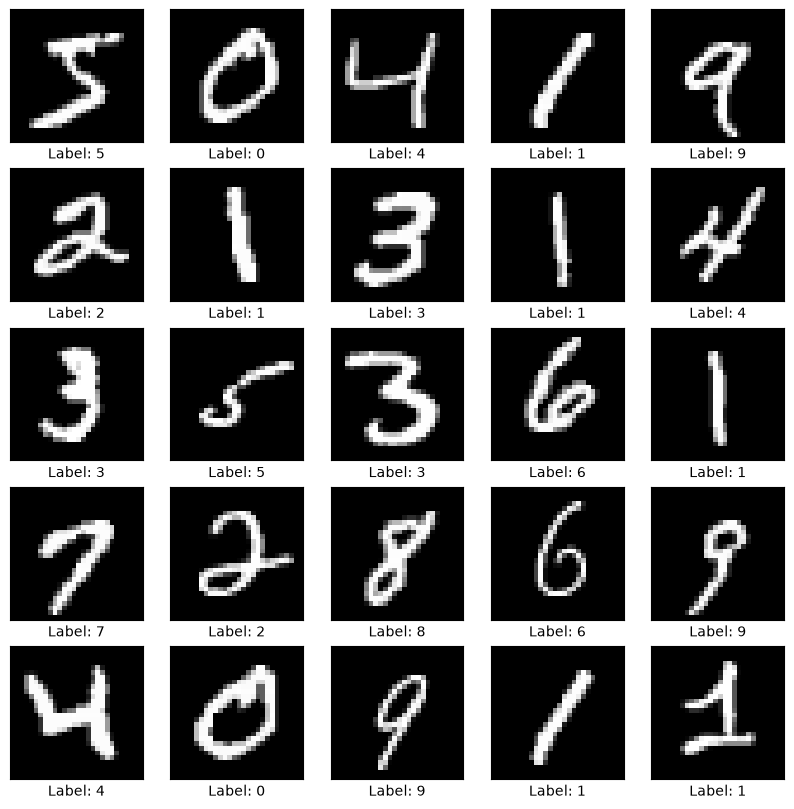

In [4]:
# Melihat contoh gambar
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(f"Label: {train_labels[i]}")
plt.show()

#### Penjelasan:
Di sini 25 gambar pertama dari data latih ditampilkan supaya kita punya gambaran seperti apa isi datasetnya. `plt.figure(figsize=(10,10))` membuat kanvas berukuran 10 x 10 inci, lalu perulangan `for i in range(25)` mengerjakan langkah yang sama untuk tiap gambar. `plt.subplot(5,5,i+1)` membagi kanvas menjadi 5 baris dan 5 kolom lalu memilih kotak ke-`i+1` untuk gambar yang sedang diproses. `plt.xticks([])` dan `plt.yticks([])` menghapus angka di sumbu, dan `plt.grid(False)` menghilangkan garis kisi, supaya gambarnya bersih.

`plt.imshow(train_images[i], cmap='gray')` menampilkan gambar ke-`i` dalam warna abu-abu, karena gambar MNIST memang hitam-putih. Lalu `plt.xlabel(...)` menulis angka yang sebenarnya di bawah tiap gambar. Bagian label ini tambahan dari saya, supaya kita bisa langsung membandingkan gambar dengan jawabannya. `plt.show()` menampilkan hasilnya.

Kalau diperhatikan, tulisan tangan tiap orang berbeda-beda. Ada yang rapi, ada yang miring, dan ada yang tidak jelas. Inilah yang membuat tugas ini menarik, karena model harus tetap bisa mengenali angkanya walaupun bentuk tulisannya beragam.

In [5]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Input(shape=(28, 28)),           # Menentukan bentuk input: gambar 28x28 piksel
    Flatten(),                       # Mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),   # Hidden layer dengan 128 neuron
    Dense(10, activation='softmax')  # Output layer dengan 10 neuron untuk klasifikasi 10 angka (0-9)
])

# Melihat ringkasan arsitektur model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

#### Penjelasan:
Di sinilah kita menyusun otak modelnya. `Sequential` berarti layer-layernya disusun berurutan dari input sampai output.

Layer pertama, `Input(shape=(28, 28))`, memberi tahu model bahwa data yang masuk berupa gambar 28 x 28. Di modul ini ditulis `Flatten(input_shape=(28, 28))`, yang hasilnya sama tetapi memunculkan peringatan di Keras versi baru, jadi saya memakai cara yang disarankan peringatan itu, yaitu lewat `Input`.

Layer kedua, `Flatten()`, meratakan gambar dua dimensi (28 x 28) menjadi satu baris panjang berisi 784 angka, karena 28 x 28 = 784. Ini perlu karena layer `Dense` hanya bisa menerima data berbentuk deret, bukan kotak.

Layer ketiga, `Dense(128, activation='relu')`, adalah hidden layer atau lapisan tersembunyi berisi 128 neuron. `Dense` artinya tiap neuron terhubung ke semua neuron di layer sebelumnya. Fungsi aktivasi ReLU bekerja sederhana: hasil hitungan yang negatif dijadikan 0 dan yang positif dibiarkan. Fungsi ini yang membuat model mampu mempelajari pola yang rumit, tidak hanya pola garis lurus.

Layer keempat, `Dense(10, activation='softmax')`, adalah output layer dengan 10 neuron, satu untuk tiap angka 0 sampai 9. Fungsi softmax mengubah 10 hasil itu menjadi probabilitas yang totalnya 1 atau 100%. Contohnya angka 7 mendapat 95%, angka 1 mendapat 3%, dan sisanya kecil-kecil. Angka dengan probabilitas tertinggi menjadi hasil tebakan model.

Pada `model.summary()`, layer `flatten` punya 0 parameter karena hanya meratakan data dan tidak ada yang dipelajari. Hidden layer `dense` punya 100.480 parameter, yaitu 784 x 128 = 100.352 bobot ditambah 128 bias. Output layer `dense_1` punya 1.290 parameter, yaitu 128 x 10 = 1.280 bobot ditambah 10 bias. Totalnya 101.770 parameter, dan semuanya akan disesuaikan oleh model selama belajar. Tulisan `None` pada output shape artinya jumlah data per batch bisa berapa saja.

In [6]:
# Kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model dengan data training
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9241 - loss: 0.2635 - val_accuracy: 0.9572 - val_loss: 0.1427
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9655 - loss: 0.1142 - val_accuracy: 0.9718 - val_loss: 0.0983
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9763 - loss: 0.0789 - val_accuracy: 0.9742 - val_loss: 0.0829
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9816 - loss: 0.0598 - val_accuracy: 0.9761 - val_loss: 0.0752
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9854 - loss: 0.0472 - val_accuracy: 0.9778 - val_loss: 0.0706
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9883 - loss: 0.0372 - val_accuracy: 0.9755 - val_loss: 0.0763
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9906 - loss: 0.0297 - val_accuracy: 0.9776 - val_loss: 0.0737
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9926 - loss: 0.0242 - 

#### Penjelasan:
`model.compile(...)` menyiapkan aturan belajar sebelum model dilatih. `optimizer='adam'` menentukan cara model memperbaiki bobotnya, dan Adam dipilih karena cepat serta cukup stabil sehingga cocok untuk pemula. `loss='sparse_categorical_crossentropy'` menentukan cara mengukur seberapa salah tebakan model. Ini dipakai karena kasusnya klasifikasi banyak kelas dan label kita berupa angka biasa (0 sampai 9). Kalau labelnya sudah diubah ke bentuk one-hot, barulah dipakai `categorical_crossentropy`. Terakhir, `metrics=['accuracy']` membuat akurasi ikut ditampilkan supaya kita bisa memantau persentase tebakan yang benar.

`model.fit(...)` adalah proses melatih modelnya. Model diberi `train_images` beserta jawabannya, `train_labels`, lalu `epochs=10` berarti model melihat seluruh 60.000 gambar latih sebanyak 10 putaran, dan bobotnya disempurnakan lagi di tiap putaran. `validation_data=(test_images, test_labels)` membuat model dicoba ke data uji setelah tiap epoch, untuk melihat apakah ia benar-benar belajar atau hanya menghafal. Memakai data uji sebagai validasi seperti ini mengikuti modul, dan untuk keperluan praktikum sudah cukup. Semua catatan hasilnya disimpan di `history` supaya nanti bisa dibuat grafik.

Output tiap epoch bisa dibaca seperti ini. Angka `1875/1875` adalah jumlah batch per epoch. Keras secara default memproses 32 gambar sekali jalan, jadi 60.000 dibagi 32 hasilnya 1.875 langkah. `accuracy` dan `loss` adalah akurasi dan kesalahan pada data latih, sedangkan `val_accuracy` dan `val_loss` adalah akurasi dan kesalahan pada data uji. Yang diharapkan, `accuracy` naik dan `loss` turun seiring bertambahnya epoch.

In [7]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest loss     : {test_loss}')
print(f'Test accuracy : {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9789 - loss: 0.0786

Test loss     : 0.07859346270561218
Test accuracy : 0.9789000153541565


#### Penjelasan:
`model.evaluate(...)` menguji model yang sudah selesai dilatih memakai 10.000 data uji, lalu mengembalikan `test_loss` (tingkat kesalahan) dan `test_acc` (akurasi). Cara membacanya sama seperti `accuracy_score` di praktikum KNN dan Naïve Bayes. Misalnya `test_acc` bernilai 0.97, artinya dari 100 gambar angka yang belum pernah dilihat model saat belajar, sekitar 97 ditebak dengan benar.

Untuk model sederhana seperti ini di dataset MNIST, akurasi yang umumnya didapat ada di kisaran 97 sampai 98%. Angka persisnya bisa berbeda sedikit tiap kali dijalankan, karena bobot awal model dibuat acak.

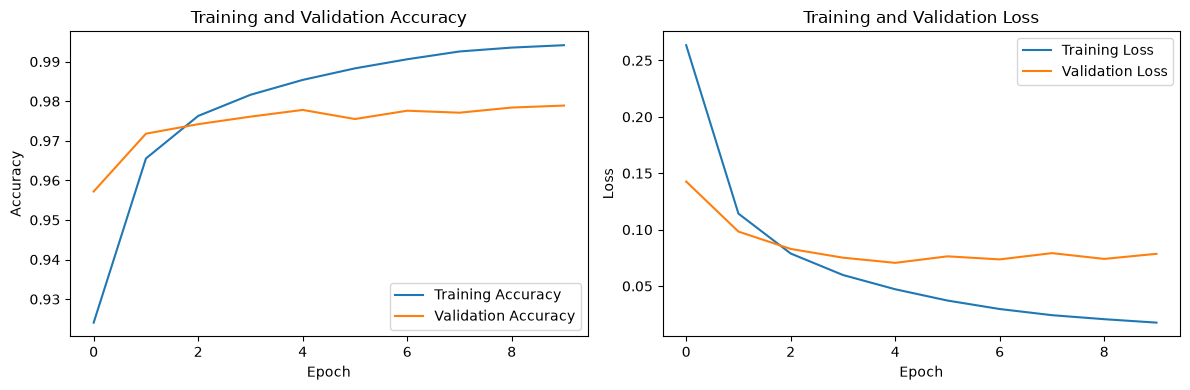

In [8]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

#### Penjelasan:
Bagian ini membuat fungsi `plot_history` untuk menggambar perkembangan belajar model. Dibuat sebagai fungsi supaya kodenya rapi dan bisa dipanggil ulang kapan saja. Datanya diambil dari `history.history`, yaitu catatan akurasi dan loss tiap epoch yang disimpan saat `model.fit()`.

Hasilnya dua grafik berdampingan (`plt.subplot(1, 2, ...)` artinya 1 baris dan 2 kolom). Grafik kiri menunjukkan akurasi data latih (`accuracy`) dan data uji (`val_accuracy`) di setiap epoch, sedangkan grafik kanan menunjukkan kesalahan data latih (`loss`) dan data uji (`val_loss`). `plt.tight_layout()` merapikan jarak antar grafik supaya tulisannya tidak bertabrakan.

Cara membacanya: akurasi yang naik dan loss yang turun berarti model sedang belajar. Kalau garis training dan validation berdekatan, modelnya seimbang. Kalau garis training terus naik tapi validation mendatar atau malah turun, dan loss validation mulai naik, itu tanda overfitting, yaitu model mulai menghafal data latih dan bukan memahami polanya.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step


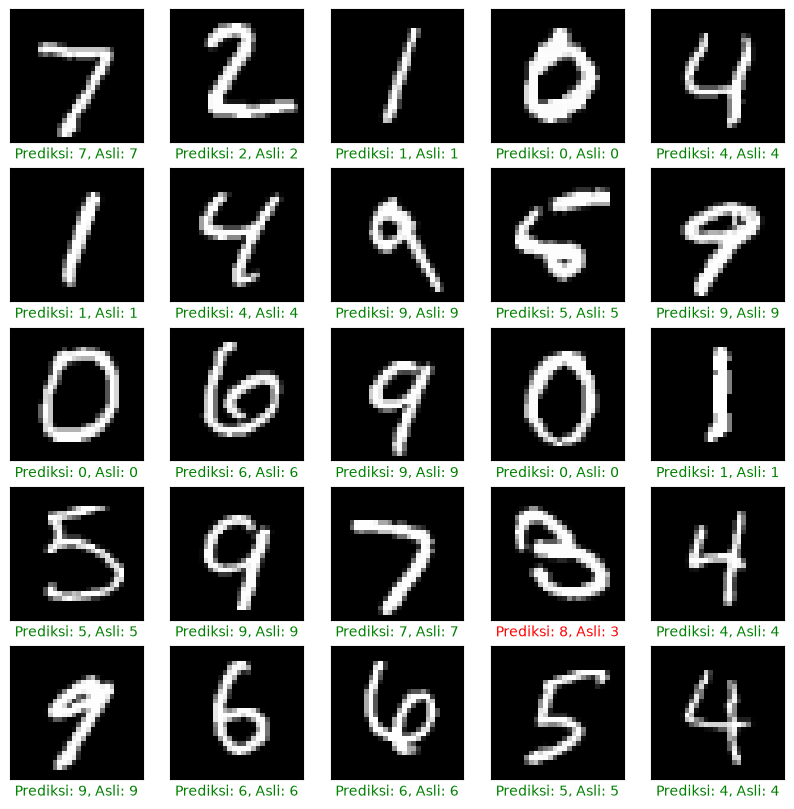

In [9]:
# Melakukan prediksi pada gambar pengujian
predictions = model.predict(test_images)

# Contoh prediksi untuk 25 gambar pertama
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    # Hijau jika tebakan benar, merah jika salah
    warna = 'green' if predicted_label == actual_label else 'red'
    plt.xlabel(f"Prediksi: {predicted_label}, Asli: {actual_label}", color=warna)
plt.show()

#### Penjelasan:
`model.predict(test_images)` membuat model menebak seluruh 10.000 gambar uji. Hasilnya disimpan di `predictions`, berbentuk tabel `(10000, 10)`: tiap gambar punya 10 angka probabilitas (hasil softmax), satu untuk tiap kemungkinan angka 0 sampai 9.

Setelah itu 25 gambar uji pertama ditampilkan beserta tebakannya. `np.argmax(predictions[i])` mencari nomor urut dengan probabilitas tertinggi dari 10 angka tadi. Karena urutan neuron output kita adalah 0 sampai 9, nomor itu langsung menjadi angka tebakan model. Misalnya kalau probabilitas terbesar ada di urutan ke-7, berarti model menebak angka 7. `actual_label = test_labels[i]` adalah angka yang sebenarnya. Di bawah tiap gambar tertulis prediksi dan angka aslinya, dan saya menambahkan warna: hijau kalau tebakannya benar dan merah kalau salah, supaya langsung terlihat.

Kalau mayoritas tulisan berwarna hijau, berarti modelnya sudah pandai mengenali angka. Kalau ada yang merah, biasanya karena tulisan tangannya memang ambigu, misalnya angka 4 yang mirip 9, atau angka 7 yang mirip 1.

In [10]:
# Lihat probabilitas hasil softmax untuk gambar pertama
print('Probabilitas tiap angka (0-9):')
print(np.round(predictions[0], 4))
print('Total probabilitas:', predictions[0].sum())
print('Tebakan model:', np.argmax(predictions[0]), '| Angka asli:', test_labels[0])

# Hitung jumlah tebakan yang salah pada seluruh data uji
tebakan = np.argmax(predictions, axis=1)
jumlah_salah = np.sum(tebakan != test_labels)
print(f'\nJumlah tebakan salah: {jumlah_salah} dari {len(test_labels)} data uji')

Probabilitas tiap angka (0-9):
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
Total probabilitas: 1.0
Tebakan model: 7 | Angka asli: 7

Jumlah tebakan salah: 211 dari 10000 data uji


#### Penjelasan:
Cell ini tambahan dari saya untuk membantu memahami apa yang sebenarnya dihasilkan model. `predictions[0]` berisi 10 angka probabilitas untuk gambar uji pertama. Biasanya satu angka nilainya sangat dekat ke 1, artinya model sangat yakin, sedangkan sisanya mendekati 0. `np.round(..., 4)` hanya membulatkan supaya mudah dibaca. `predictions[0].sum()` menunjukkan bahwa total probabilitasnya 1 atau 100%, karena itulah sifat softmax. Kadang tertulis `0.99999994` atau semacamnya, itu bukan salah, hanya pembulatan angka desimal di komputer.

Bagian kedua menghitung jumlah tebakan yang salah. `np.argmax(predictions, axis=1)` mencari tebakan untuk semua gambar uji sekaligus (`axis=1` artinya dicari per baris, yaitu per gambar). Lalu `tebakan != test_labels` menghasilkan `True` untuk tebakan yang salah, dan `np.sum(...)` menjumlahkan semua yang `True`, sehingga didapat total tebakan yang salah. Hasilnya konsisten dengan akurasi tadi. Contohnya kalau akurasinya 97,5%, maka sekitar 250 dari 10.000 gambar yang salah ditebak.

## Kesimpulan yang saya dapat

Pada praktikum ini saya membuat Neural Network sederhana untuk mengenali angka tulisan tangan memakai dataset MNIST, sebagai pengganti dataset Fashion MNIST yang dipakai di modul. Dataset ini terdiri dari 60.000 gambar latih dan 10.000 gambar uji berukuran 28 x 28 piksel hitam-putih.

Langkah yang saya kerjakan dimulai dari memuat dataset, lalu menormalisasi nilai piksel dari rentang 0 sampai 255 menjadi 0 sampai 1 agar model belajar lebih stabil. Modelnya terdiri dari layer `Flatten` yang meratakan gambar menjadi 784 angka, satu hidden layer `Dense` dengan 128 neuron dan aktivasi ReLU, serta output layer `Dense` dengan 10 neuron dan aktivasi softmax, dengan total 101.770 parameter. Model dikompilasi memakai optimizer Adam dan loss `sparse_categorical_crossentropy`, lalu dilatih selama 10 epoch. Setelah itu saya mengevaluasinya dengan data uji, menggambar grafik akurasi dan loss, dan memakai model untuk memprediksi gambar-gambar uji.

Test accuracy yang saya dapatkan adalah **(isi sesuai hasil di komputer kamu)**.

Dari praktikum ini saya belajar bahwa data gambar perlu dinormalisasi sebelum dilatih, dan bahwa jumlah neuron di output layer harus sama dengan jumlah kelas yang mau ditebak. Arsitektur model dan jumlah epoch juga mempengaruhi seberapa baik hasilnya. Grafik training dan validation berguna untuk mengecek apakah model sudah belajar dengan baik atau mulai overfitting. Dibandingkan KNN dan Naïve Bayes, Neural Network lebih fleksibel dan cocok untuk data gambar, tetapi proses pelatihannya lebih lama.